# Diplomado en Ciencia de Datos y Análisis Avanzado - UTN.BA
## Módulo 4: Visualización de Datos
### Trabajo Práctico: Análisis geoespacial de Energías Renovables, Red de Alta Tensión y Demanda Eléctrica en Argentina

---

**Integrantes del Grupo (por orden alfabético de apellido):**
* **Nouvard, Ezequiel**
* **Ojeda, Wanda**
* **Passero, Genaro Agustín** *(Responsable de realizar la entrega)*
* **Urbina Salazar, Laida**

**Responsable de la entrega:** Passero, Genaro Agustín

---

### Introducción y planteo del problema

En Argentina, la generación de energías renovables tiene una distribución geográfica muy marcada por el clima de cada región: en el Norte (NOA y Cuyo) predominan los **parques solares** por la radiación solar, mientras que en el Sur (Patagonia y sur de Buenos Aires) se concentran los **parques eólicos** por los vientos constantes.

Sin embargo, el mayor consumo de energía eléctrica se concentra en el centro del país (principalmente en Buenos Aires, Córdoba y Santa Fe). Para transportar la electricidad cientos de kilómetros sin que pierda fuerza (caída de tensión y pérdidas por calor en los cables), los parques necesitan conectarse a **Estaciones Transformadoras (Subestaciones)** que eleven la tensión a niveles de Alta Tensión (132 kV a 500 kV).

**Objetivos del trabajo:**
1. Analizar la distribución espacial de los parques de energías renovables según su tecnología (Norte solar vs. Sur eólico).
2. Medir con herramientas geoespaciales (cKDTree) a cuántos kilómetros se encuentra cada parque renovable de la **Estación Transformadora** más cercana.
3. Cruzar los datos de generación renovable y subestaciones con los polígonos de las **provincias (IGN)** y la **demanda de energía eléctrica (CAMMESA)** para identificar qué provincias generan más energía limpia en relación con lo que consumen.

**Datasets utilizados (Portal de Datos Abiertos datos.gob.ar, Secretaría de Energía e IGN):**
* **Tabla 1 (centrales_generacion.csv):** Ubicación geográfica, tecnología y potencia instalada (MW) de las centrales eléctricas del país.
* **Tabla 2 (estaciones_transformadoras.shp y lineas_alta_tension.shp):** Coordenadas de las Estaciones Transformadoras y trazado de las líneas de Alta Tensión del Sistema Argentino de Interconexión (SADI).
* **Tabla 3 (ign_provincia.shp y cammesa_demanda_ultimos_anios.csv):** Polígonos provinciales del Instituto Geográfico Nacional (IGN) y consumo eléctrico por provincia registrado por CAMMESA.

In [1]:
import os
import json
import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
from shapely.geometry import shape, box
from shapely.validation import make_valid
from scipy.spatial import cKDTree

import matplotlib.pyplot as plt
import seaborn as sns
import folium

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

DATA_DIR = 'datos'
FIG_DIR = 'figuras'
os.makedirs(FIG_DIR, exist_ok=True)

---
### 1. Carga de datos y Análisis Exploratorio (EDA)

Cargamos las tablas con `pandas` y `geopandas` y revisamos su estructura (`shape`), tipos de geometría (`geom_type`), sistema de coordenadas (`crs`) y valores faltantes.

In [2]:
# 1. Cargar tabla de centrales eléctricas y convertir la columna geojson a geometría de puntos
df_centrales = pd.read_csv(os.path.join(DATA_DIR, 'centrales_generacion.csv'))
df_centrales['geometry'] = df_centrales['geojson'].apply(lambda x: shape(json.loads(x)))
gdf_centrales = gpd.GeoDataFrame(df_centrales, geometry='geometry', crs='EPSG:4326')

# 2. Cargar capas de Estaciones Transformadoras (Subestaciones) y Líneas de Alta Tensión
gdf_subestaciones = gpd.read_file(os.path.join(DATA_DIR, 'estaciones_transformadoras_shp', 'estaciones_transformadoras.shp'))
gdf_lineas = gpd.read_file(os.path.join(DATA_DIR, 'lineas_alta_tension_shp', 'lineas_alta_tension.shp'))

# 3. Cargar polígonos de Provincias (IGN) y tabla de Demanda Eléctrica (CAMMESA)
gdf_provincias = gpd.read_file(os.path.join(DATA_DIR, 'ign_provincia', 'Provincia', 'ign_provincia.shp'))
df_demanda = pd.read_csv(os.path.join(DATA_DIR, 'cammesa_demanda_ultimos_anios.csv'))

print("Centrales eléctricas:", gdf_centrales.shape, "| CRS:", gdf_centrales.crs)
print("Subestaciones AT:    ", gdf_subestaciones.shape, "| CRS:", gdf_subestaciones.crs)
print("Líneas de AT:        ", gdf_lineas.shape, "| CRS:", gdf_lineas.crs)
print("Provincias IGN:      ", gdf_provincias.shape, "| CRS:", gdf_provincias.crs)
print("Demanda CAMMESA:     ", df_demanda.shape)

Centrales eléctricas: (474, 17) | CRS: EPSG:4326
Subestaciones AT:     (323, 10) | CRS: EPSG:4326
Líneas de AT:         (1299, 11) | CRS: EPSG:4326
Provincias IGN:       (24, 12) | CRS: EPSG:4326
Demanda CAMMESA:      (40388, 16)


In [3]:
# Exploramos qué tipos de tecnologías hay en el dataset de centrales
print("Cantidad de centrales por tecnología:")
print(gdf_centrales['tecnologia_etiqueta'].value_counts())

print("\nTipos de geometría en Subestaciones y Líneas:")
print("Subestaciones:", gdf_subestaciones.geom_type.value_counts().to_dict())
print("Líneas AT:    ", gdf_lineas.geom_type.value_counts().to_dict())

Cantidad de centrales por tecnología:
tecnologia_etiqueta
Térmica                           205
Fotovoltaica                       84
Eólica                             71
Hidroeléctrica (Menor a 50 Mw)     41
Biogas                             33
Hidroeléctrica                     21
Biomasa                            17
Nuclear                             2
Name: count, dtype: int64

Tipos de geometría en Subestaciones y Líneas:
Subestaciones: {'MultiPoint': 323}
Líneas AT:     {'LineString': 1247, 'MultiLineString': 50}


---
### 2. Preprocesamiento y limpieza de datos

Para poder cruzar las capas y medir distancias correctamente aplicamos los siguientes pasos de preprocesamiento:

1. **Filtro de Energías Renovables e imputación de valores faltantes:** Filtramos las centrales renovables (`Fotovoltaica`, `Eólica`, `Biogas`, `Biomasa` e `Hidroeléctrica (Menor a 50 Mw)`). Como algunas centrales tienen el valor de potencia (`potencia_instalada_mw`) en nulo (`NaN`), completamos esos faltantes usando la **mediana de potencia de cada tecnología**, para no perder esos puntos en el mapa ni distorsionar con valores extremos.
2. **Validación de geometrías y recorte continental:** Aplicamos `make_valid` sobre las provincias y recortamos con `gpd.clip` la parte continental de Argentina (excluyendo la Antártida) para que el mapa nacional se visualice en la escala correcta.
3. **Reproyección a coordenadas en metros (`EPSG:32720` - UTM Zona 20S):** Como vimos en clase, `EPSG:4326` está en grados y no sirve para medir distancias ni áreas. Reproyectamos todas las capas a `EPSG:32720` (metros). Además, pasamos las geometrías de `gdf_subestaciones` de `MultiPoint` a `Point` usando `.centroid`.
4. **Estandarización de nombres de provincias:** Llevamos los nombres de provincias a mayúsculas sin tildes para poder unir (`merge`) los datos del IGN con la tabla de CAMMESA (unificando Buenos Aires y CABA porque CAMMESA informa el consumo de EDENOR y EDESUR dentro de Buenos Aires).

In [4]:
# 1. Filtrar solo los parques de energías renovables
tecnologias_renovables = [
    'Fotovoltaica',
    'Eólica',
    'Hidroeléctrica (Menor a 50 Mw)',
    'Biogas',
    'Biomasa'
]
gdf_parques = gdf_centrales[gdf_centrales['tecnologia_etiqueta'].isin(tecnologias_renovables)].copy()

# Agrupar nombres de tecnología más cortos para los gráficos
mapa_nombres_tec = {
    'Fotovoltaica': 'Solar Fotovoltaica',
    'Eólica': 'Eólica',
    'Hidroeléctrica (Menor a 50 Mw)': 'Pequeño Aprov. Hidro (PAH)',
    'Biogas': 'Bioenergía (Biogás/Biomasa)',
    'Biomasa': 'Bioenergía (Biogás/Biomasa)'
}
gdf_parques['tecnologia_limpia'] = gdf_parques['tecnologia_etiqueta'].map(mapa_nombres_tec)

# Imputar potencia faltante con la mediana de cada tecnología
print("Valores nulos en potencia antes de imputar:", gdf_parques['potencia_instalada_mw'].isna().sum())
medianas_potencia = gdf_parques.groupby('tecnologia_limpia')['potencia_instalada_mw'].transform('median')
gdf_parques['potencia_mw'] = gdf_parques['potencia_instalada_mw'].fillna(medianas_potencia)
print("Valores nulos en potencia después de imputar:", gdf_parques['potencia_mw'].isna().sum())

# Extraer latitud y longitud para el análisis exploratorio
gdf_parques['latitud'] = gdf_parques.geometry.y
gdf_parques['longitud'] = gdf_parques.geometry.x

print("Total de parques renovables:", len(gdf_parques))
gdf_parques[['nombre', 'provincia', 'tecnologia_limpia', 'potencia_mw', 'latitud', 'longitud']].head()

Valores nulos en potencia antes de imputar: 89
Valores nulos en potencia después de imputar: 0
Total de parques renovables: 246


,nombre,provincia,tecnologia_limpia,potencia_mw,latitud,longitud
0,EL TUNAL,SALTA,Pequeño Aprov. Hidro (PAH),10.52,-25.227032,-64.476431
2,CORRALITO,SALTA,Pequeño Aprov. Hidro (PAH),7.20,-24.983034,-65.686527
3,LOS MADERAS,JUJUY,Pequeño Aprov. Hidro (PAH),30.60,-24.444199,-65.219736
4,RIO REYES,JUJUY,Pequeño Aprov. Hidro (PAH),7.00,-24.169484,-65.491635
7,SMARTIN TABACAL,SALTA,Bioenergía (Biogás/Biomasa),2.00,-23.253761,-64.241097


In [5]:
# 2. Limpieza de geometrías nulas en Líneas y Subestaciones
gdf_subestaciones = gdf_subestaciones[gdf_subestaciones.geometry.notna()].copy()
gdf_lineas = gdf_lineas[gdf_lineas.geometry.notna()].copy()
gdf_lineas['tension_kv'] = pd.to_numeric(gdf_lineas['TENSION'], errors='coerce').fillna(132)

# 3. Validar geometrías de provincias y recortar al continente (sin Antártida)
gdf_provincias['geometry'] = gdf_provincias.geometry.apply(
    lambda g: make_valid(g) if not g.is_valid else g
)
caja_continental = box(-76.0, -56.0, -52.0, -21.0)
gdf_provincias = gpd.clip(gdf_provincias, caja_continental).copy()

# Normalizar nombres de provincias para cruzar las tablas sin errores de tildes
reemplazos_prov = {
    'Á': 'A', 'É': 'E', 'Í': 'I', 'Ó': 'O', 'Ú': 'U',
    'SGO.DEL ESTERO': 'SANTIAGO DEL ESTERO',
    'TIERRA DEL FUEGO, ANTARTIDA E ISLAS DEL ATLANTICO SUR': 'TIERRA DEL FUEGO',
    'CIUDAD AUTONOMA DE BUENOS AIRES': 'BUENOS AIRES'
}

def limpiar_provincia(nombre):
    if pd.isna(nombre):
        return 'SIN DATOS'
    texto = str(nombre).strip().upper()
    for viejo, nuevo in reemplazos_prov.items():
        texto = texto.replace(viejo, nuevo)
    return texto

gdf_provincias['provincia'] = gdf_provincias['NAM'].apply(limpiar_provincia)
gdf_parques['provincia'] = gdf_parques['provincia'].apply(limpiar_provincia)
df_demanda['provincia'] = df_demanda['provincia'].apply(limpiar_provincia)

# Unir el polígono de CABA con Buenos Aires con dissolve para que coincida con CAMMESA
gdf_provincias = gdf_provincias.dissolve(by='provincia', as_index=False)

# 4. Reproyectar todas las capas a EPSG:32720 (UTM Zona 20S en metros)
gdf_parques_utm = gdf_parques.to_crs(epsg=32720)
gdf_subestaciones_utm = gdf_subestaciones.to_crs(epsg=32720)
gdf_subestaciones_utm['geometry'] = gdf_subestaciones_utm.geometry.centroid  # Pasar MultiPoint a Point
gdf_lineas_utm = gdf_lineas.to_crs(epsg=32720)
gdf_provincias_utm = gdf_provincias.to_crs(epsg=32720)

# Calcular el área de cada provincia en km2 y la longitud de cada línea en km
gdf_provincias_utm['area_km2'] = gdf_provincias_utm.geometry.area / 1e6
gdf_lineas_utm['longitud_km'] = gdf_lineas_utm.geometry.length / 1000

print("Capas reproyectadas a:", gdf_parques_utm.crs)

Capas reproyectadas a: EPSG:32720


---
### 3. Análisis espacial: Proximidad a Subestaciones (`cKDTree`) y Cruce por Provincia (`Spatial Join`)

#### 3.1. Distancia de cada parque renovable a la Subestación más cercana (`cKDTree`)
Aplicamos el método `cKDTree` de `scipy.spatial` visto en la Unidad 1 para encontrar de forma rápida cuál es la Estación Transformadora más cercana a cada parque renovable y a cuántos kilómetros se encuentra. Luego clasificamos esa distancia en rangos de cobertura.

In [6]:
# Obtener coordenadas (X, Y) en metros de las subestaciones y de los parques
coords_sub = np.array([(g.x, g.y) for g in gdf_subestaciones_utm.geometry])
coords_parq = np.array([(g.x, g.y) for g in gdf_parques_utm.geometry])

# Crear el árbol de búsqueda espacial con las subestaciones
tree = cKDTree(coords_sub)

# Consultar la subestación más cercana (k=1) para cada parque
dist, idx = tree.query(coords_parq, k=1)

# Guardar la distancia en km y el nombre de la subestación más cercana
gdf_parques['dist_subestacion_km'] = dist / 1000
gdf_parques['subestacion_cercana'] = gdf_subestaciones_utm.iloc[idx]['NOMBRE'].values

# Clasificar la cercanía a una subestación (siguiendo el criterio visto en clase)
def clasificar_cercania(d):
    if d <= 10:
        return 'Alta (<= 10 km)'
    elif d <= 30:
        return 'Media (10 a 30 km)'
    elif d <= 60:
        return 'Baja (30 a 60 km)'
    else:
        return 'Alejada (> 60 km)'

gdf_parques['cobertura_red'] = gdf_parques['dist_subestacion_km'].apply(clasificar_cercania)

# Ver resumen de distancias por tecnología
resumen_distancias = gdf_parques.groupby('tecnologia_limpia').agg(
    cantidad_parques=('nombre', 'count'),
    potencia_total_mw=('potencia_mw', 'sum'),
    distancia_mediana_km=('dist_subestacion_km', 'median'),
    distancia_promedio_km=('dist_subestacion_km', 'mean')
).round(2)

print(resumen_distancias)
print("\nCantidad de parques según cercanía a una Estación Transformadora:")
print(gdf_parques['cobertura_red'].value_counts())

                             cantidad_parques  potencia_total_mw  \
tecnologia_limpia                                                  
Bioenergía (Biogás/Biomasa)                50             173.48   
Eólica                                     71            4050.06   
Pequeño Aprov. Hidro (PAH)                 41             485.41   
Solar Fotovoltaica                         84            1577.23   

                             distancia_mediana_km  distancia_promedio_km  
tecnologia_limpia                                                         
Bioenergía (Biogás/Biomasa)                 46.90                  69.03  
Eólica                                      24.34                  35.13  
Pequeño Aprov. Hidro (PAH)                   9.88                  31.32  
Solar Fotovoltaica                          31.69                  56.24  

Cantidad de parques según cercanía a una Estación Transformadora:
cobertura_red
Alejada (> 60 km)     74
Alta (<= 10 km)       71
Media (10 

#### 3.2. Spatial Join (`gpd.sjoin`) y unión con el consumo eléctrico por provincia
Usamos `gpd.sjoin` para contar cuántas subestaciones caen dentro del polígono de cada provincia, y luego unimos con `.merge()` la potencia renovable instalada y la demanda eléctrica anual de CAMMESA.

In [7]:
# 1. Spatial Join: asignar a cada subestación la provincia en la que cae
joined_sub = gpd.sjoin(
    gdf_subestaciones_utm,
    gdf_provincias_utm[['provincia', 'geometry']],
    how='left',
    predicate='within'
)
conteo_sub = joined_sub.groupby('provincia').size().reset_index(name='n_subestaciones')

# 2. Sumar potencia renovable (MW) y cantidad de parques por provincia
parques_por_prov = gdf_parques.groupby('provincia').agg(
    n_parques=('nombre', 'count'),
    potencia_renovable_mw=('potencia_mw', 'sum'),
    potencia_solar_mw=('potencia_mw', lambda s: s[gdf_parques.loc[s.index, 'tecnologia_limpia'] == 'Solar Fotovoltaica'].sum()),
    potencia_eolica_mw=('potencia_mw', lambda s: s[gdf_parques.loc[s.index, 'tecnologia_limpia'] == 'Eólica'].sum()),
    dist_mediana_sub_km=('dist_subestacion_km', 'median')
).reset_index()

# 3. Calcular la demanda eléctrica anual promedio (en GWh) por provincia con los datos de CAMMESA (2017-2019)
demanda_anual = (
    df_demanda[df_demanda['anio'].isin([2017, 2018, 2019])]
    .groupby(['provincia', 'anio'])['demanda_MWh']
    .sum()
    .groupby('provincia')
    .mean() / 1000  # pasamos de MWh a GWh
).reset_index(name='demanda_anual_gwh')

# 4. Unir todas las tablas al GeoDataFrame de provincias
gdf_prov_datos = gdf_provincias_utm[['provincia', 'area_km2', 'geometry']].merge(conteo_sub, on='provincia', how='left')
gdf_prov_datos = gdf_prov_datos.merge(parques_por_prov, on='provincia', how='left')
gdf_prov_datos = gdf_prov_datos.merge(demanda_anual, on='provincia', how='left')

# Rellenar con 0 las provincias que no tengan parques o registros
columnas_num = ['n_subestaciones', 'n_parques', 'potencia_renovable_mw', 'potencia_solar_mw', 'potencia_eolica_mw', 'dist_mediana_sub_km', 'demanda_anual_gwh']
gdf_prov_datos[columnas_num] = gdf_prov_datos[columnas_num].fillna(0)

# Calcular el ratio de Potencia Renovable cada 1000 GWh de demanda (para comparar provincias grandes y chicas)
gdf_prov_datos['mw_renovable_por_1000gwh'] = np.where(
    gdf_prov_datos['demanda_anual_gwh'] > 0,
    (gdf_prov_datos['potencia_renovable_mw'] / gdf_prov_datos['demanda_anual_gwh']) * 1000,
    0
)

# Guardar tabla resumen en CSV
gdf_prov_datos.drop(columns='geometry').sort_values('potencia_renovable_mw', ascending=False).to_csv(
    os.path.join(DATA_DIR, 'resumen_provincial_energia.csv'), index=False
)

gdf_prov_datos.drop(columns='geometry').sort_values('potencia_renovable_mw', ascending=False).head(12).round(1)

,provincia,area_km2,n_subestaciones,n_parques,potencia_renovable_mw,potencia_solar_mw,potencia_eolica_mw,dist_mediana_sub_km,demanda_anual_gwh,mw_renovable_por_1000gwh
0,BUENOS AIRES,305983.0,105.0,42.0,1772.0,0.0,1735.4,28.0,64716.2,27.4
3,CHUBUT,225321.4,22.0,23.0,1273.2,0.0,1226.4,10.2,4522.3,281.5
16,SAN JUAN,88935.2,3.0,28.0,482.7,377.4,0.0,22.2,2224.6,217.0
4,CORDOBA,164631.5,6.0,30.0,405.1,55.0,229.4,71.4,9812.0,41.3
18,SANTA CRUZ,245904.3,15.0,5.0,345.9,0.0,345.9,34.1,1187.0,291.4
8,JUJUY,53314.9,9.0,5.0,337.6,300.0,0.0,144.0,1065.5,316.9
10,LA RIOJA,91815.1,11.0,12.0,313.0,112.0,201.0,6.6,1436.6,217.8
15,SALTA,155442.1,19.0,7.0,310.7,291.0,0.0,15.1,2047.8,151.7
11,MENDOZA,149950.0,11.0,22.0,164.6,94.2,0.0,17.2,5930.4,27.8
17,SAN LUIS,75442.2,1.0,16.0,163.3,105.2,50.8,106.2,1611.4,101.3


---
### 4. Visualización de Datos

#### 4.1. Mapa de la Red de Alta Tensión, Subestaciones y Parques Renovables
En el primer gráfico representamos a la izquierda la red de transporte eléctrico (diferenciando las líneas troncales de 500 kV del resto de la red y las Estaciones Transformadoras) y a la derecha la ubicación de los parques renovables según su tecnología.

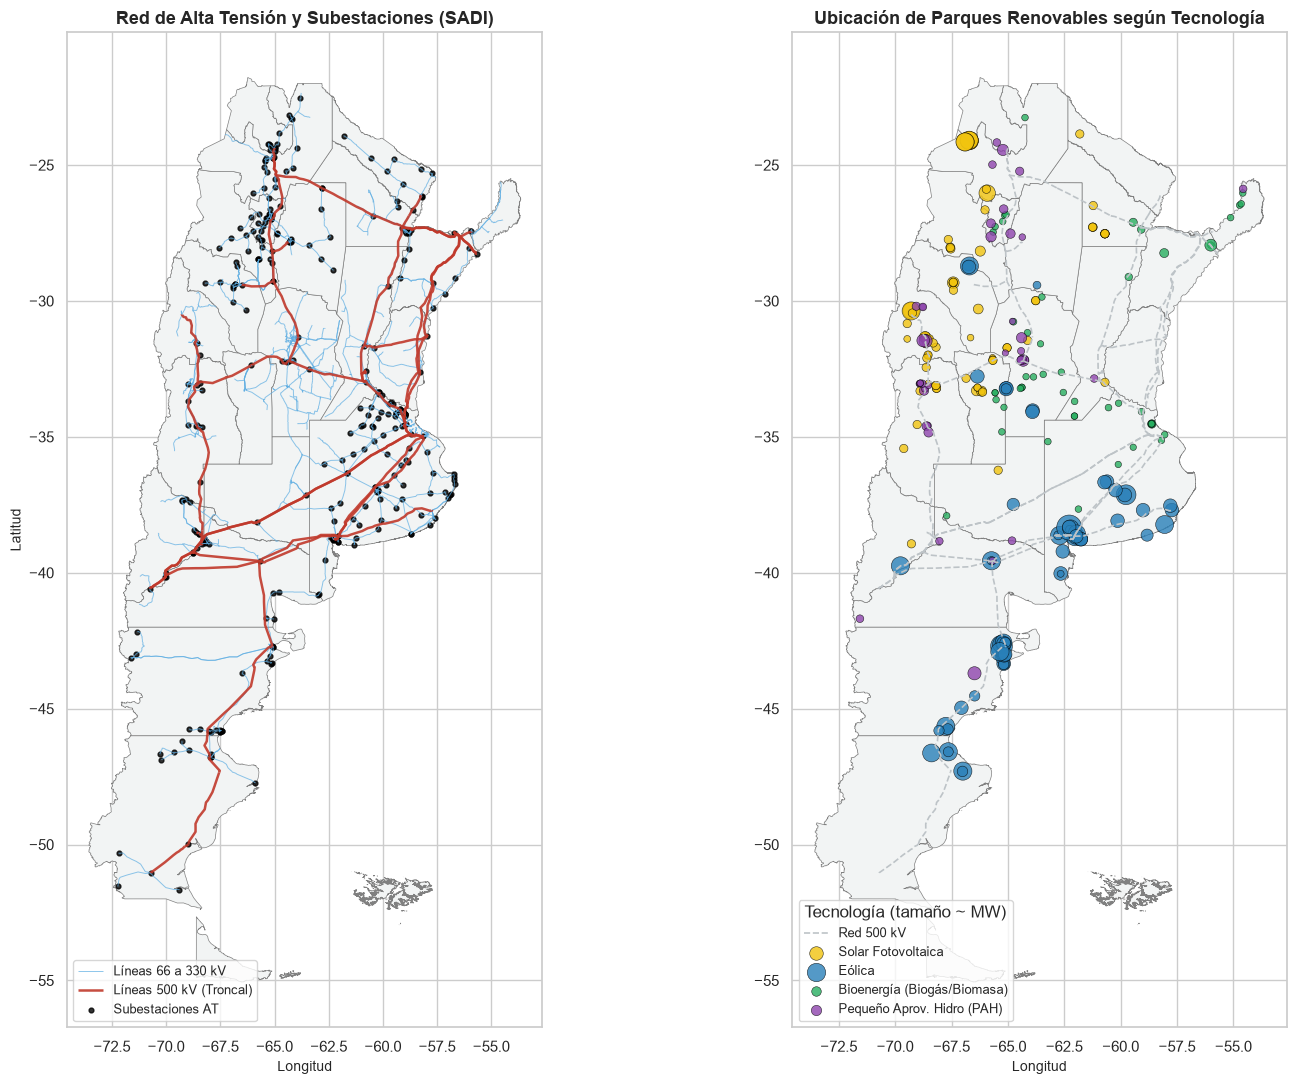

In [8]:
# Volver a EPSG:4326 para graficar mapas con latitud y longitud
gdf_prov_wgs = gdf_prov_datos.to_crs(epsg=4326)
gdf_sub_wgs = gdf_subestaciones_utm.to_crs(epsg=4326)
gdf_lineas_wgs = gdf_lineas.to_crs(epsg=4326)

fig, axes = plt.subplots(1, 2, figsize=(16, 11))

# --- Mapa 1: Red de Alta Tensión y Subestaciones ---
ax1 = axes[0]
gdf_prov_wgs.plot(ax=ax1, color='#f2f4f4', edgecolor='gray', linewidth=0.5)
gdf_lineas_wgs[gdf_lineas_wgs['tension_kv'] < 500].plot(ax=ax1, color='#5dade2', linewidth=0.7, alpha=0.7, label='Líneas 66 a 330 kV')
gdf_lineas_wgs[gdf_lineas_wgs['tension_kv'] >= 500].plot(ax=ax1, color='#c0392b', linewidth=1.8, alpha=0.9, label='Líneas 500 kV (Troncal)')
gdf_sub_wgs.plot(ax=ax1, color='black', markersize=12, alpha=0.8, label='Subestaciones AT')

ax1.set_title('Red de Alta Tensión y Subestaciones (SADI)', fontsize=13, fontweight='bold')
ax1.set_xlabel('Longitud')
ax1.set_ylabel('Latitud')
ax1.legend(loc='lower left', fontsize=9, frameon=True, facecolor='white')

# --- Mapa 2: Parques de Energías Renovables por Tecnología ---
ax2 = axes[1]
gdf_prov_wgs.plot(ax=ax2, color='#f2f4f4', edgecolor='gray', linewidth=0.5)
gdf_lineas_wgs[gdf_lineas_wgs['tension_kv'] >= 500].plot(ax=ax2, color='#bdc3c7', linewidth=1.2, linestyle='--', label='Red 500 kV')

colores_tec = {
    'Solar Fotovoltaica': '#f1c40f',
    'Eólica': '#2980b9',
    'Bioenergía (Biogás/Biomasa)': '#27ae60',
    'Pequeño Aprov. Hidro (PAH)': '#8e44ad'
}

for tec, color in colores_tec.items():
    sub = gdf_parques[gdf_parques['tecnologia_limpia'] == tec]
    sub.plot(
        ax=ax2, color=color, edgecolor='black', linewidth=0.4,
        markersize=sub['potencia_mw'] * 1.5 + 20, alpha=0.8, label=tec
    )

ax2.set_title('Ubicación de Parques Renovables según Tecnología', fontsize=13, fontweight='bold')
ax2.set_xlabel('Longitud')
ax2.set_ylabel('')
ax2.legend(loc='lower left', fontsize=9, frameon=True, facecolor='white', title='Tecnología (tamaño ~ MW)')

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_01_mapa_nacional_sadi.png'), dpi=150, bbox_inches='tight')
plt.show()

#### 4.2. Distribución por Latitud: "Norte Solar vs. Sur Eólico"
Para comprobar de forma estadística lo que se observa en el mapa, graficamos un boxplot de la latitud de los parques según su tecnología y la potencia instalada acumulada.

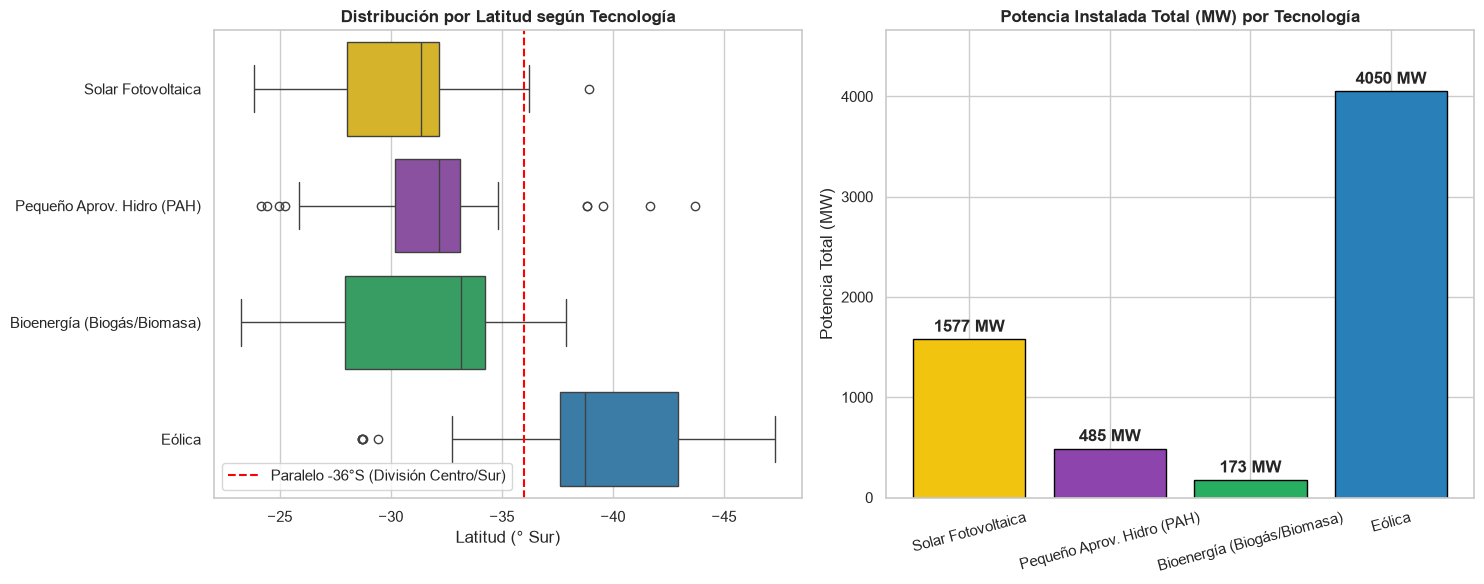

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

orden = ['Solar Fotovoltaica', 'Pequeño Aprov. Hidro (PAH)', 'Bioenergía (Biogás/Biomasa)', 'Eólica']
paleta = ['#f1c40f', '#8e44ad', '#27ae60', '#2980b9']

# Gráfico 1: Boxplot de latitud por tecnología
sns.boxplot(
    data=gdf_parques, x='latitud', y='tecnologia_limpia',
    order=orden, palette=paleta, ax=axes[0]
)
axes[0].axvline(-36, color='red', linestyle='--', label='Paralelo -36°S (División Centro/Sur)')
axes[0].invert_xaxis()  # Norte a la izquierda, Sur a la derecha
axes[0].set_title('Distribución por Latitud según Tecnología', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Latitud (° Sur)')
axes[0].set_ylabel('')
axes[0].legend(loc='lower left')

# Gráfico 2: Potencia total instalada (MW) por tecnología
potencia_tec = gdf_parques.groupby('tecnologia_limpia')['potencia_mw'].sum().reindex(orden)
barras = axes[1].bar(potencia_tec.index, potencia_tec.values, color=paleta, edgecolor='black')
axes[1].bar_label(barras, fmt='%.0f MW', fontweight='bold', padding=3)
axes[1].set_title('Potencia Instalada Total (MW) por Tecnología', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Potencia Total (MW)')
axes[1].tick_params(axis='x', rotation=15)
axes[1].set_ylim(0, potencia_tec.max() * 1.15)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_02_perfil_latitudinal_tecnologias.png'), dpi=150, bbox_inches='tight')
plt.show()

#### 4.3. Análisis de Proximidad: Distancia de los parques a las Subestaciones (`cKDTree`)
Visualizamos la distancia en kilómetros desde cada parque renovable hasta su Estación Transformadora más cercana y la cantidad de parques en cada nivel de cobertura.

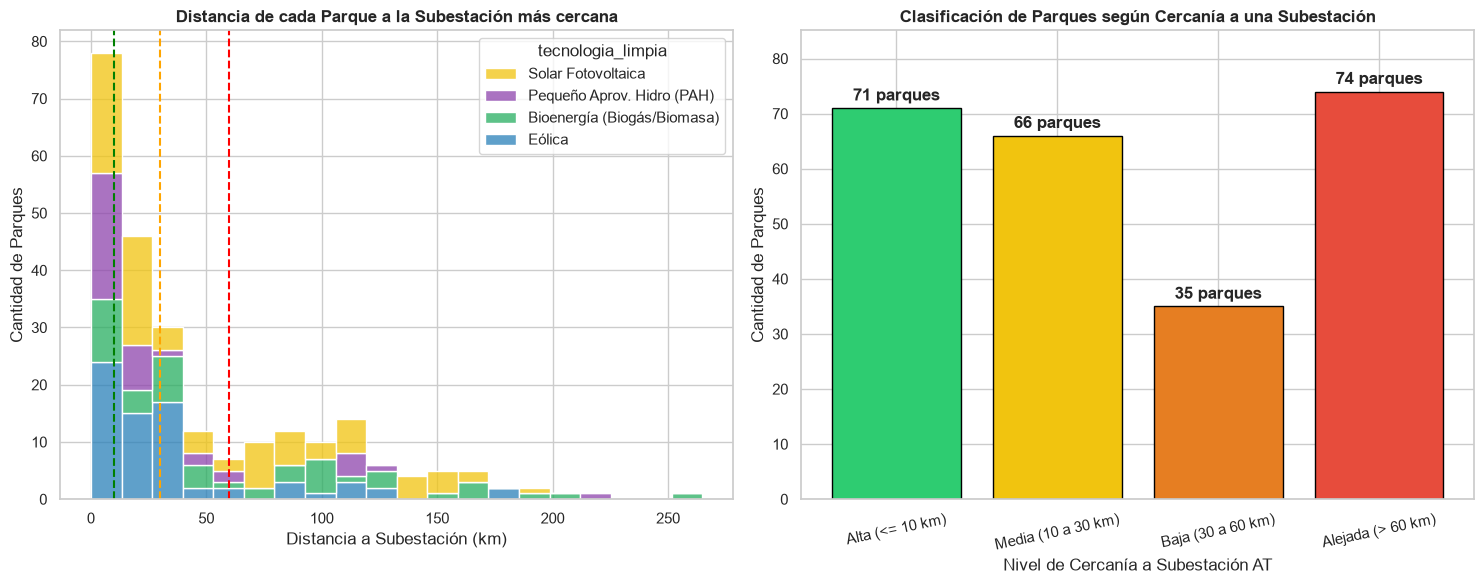

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Gráfico 1: Histograma y curva de densidad de la distancia a la subestación más cercana
sns.histplot(
    data=gdf_parques, x='dist_subestacion_km', hue='tecnologia_limpia',
    hue_order=orden, palette=paleta, multiple='stack', bins=20, ax=axes[0]
)
axes[0].axvline(10, color='green', linestyle='--', label='Alta cobertura (10 km)')
axes[0].axvline(30, color='orange', linestyle='--', label='Media cobertura (30 km)')
axes[0].axvline(60, color='red', linestyle='--', label='Baja cobertura (60 km)')
axes[0].set_title('Distancia de cada Parque a la Subestación más cercana', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Distancia a Subestación (km)')
axes[0].set_ylabel('Cantidad de Parques')

# Gráfico 2: Cantidad de parques por categoría de cobertura
orden_cob = ['Alta (<= 10 km)', 'Media (10 a 30 km)', 'Baja (30 a 60 km)', 'Alejada (> 60 km)']
colores_cob = ['#2ecc71', '#f1c40f', '#e67e22', '#e74c3c']
conteo_cob = gdf_parques['cobertura_red'].value_counts().reindex(orden_cob)

barras_cob = axes[1].bar(conteo_cob.index, conteo_cob.values, color=colores_cob, edgecolor='black')
axes[1].bar_label(barras_cob, fmt='%d parques', fontweight='bold', padding=3)
axes[1].set_title('Clasificación de Parques según Cercanía a una Subestación', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Nivel de Cercanía a Subestación AT')
axes[1].set_ylabel('Cantidad de Parques')
axes[1].tick_params(axis='x', rotation=12)
axes[1].set_ylim(0, conteo_cob.max() * 1.15)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_03_proximidad_ckdtree_subestaciones.png'), dpi=150, bbox_inches='tight')
plt.show()

#### 4.4. Comparación por Provincia: Potencia Renovable vs. Consumo de Energía Eléctrica
Graficamos dos mapas coropléticos lado a lado para comparar dónde se genera la energía renovable (`MW`) y dónde se consume la electricidad (`GWh` anuales según CAMMESA).

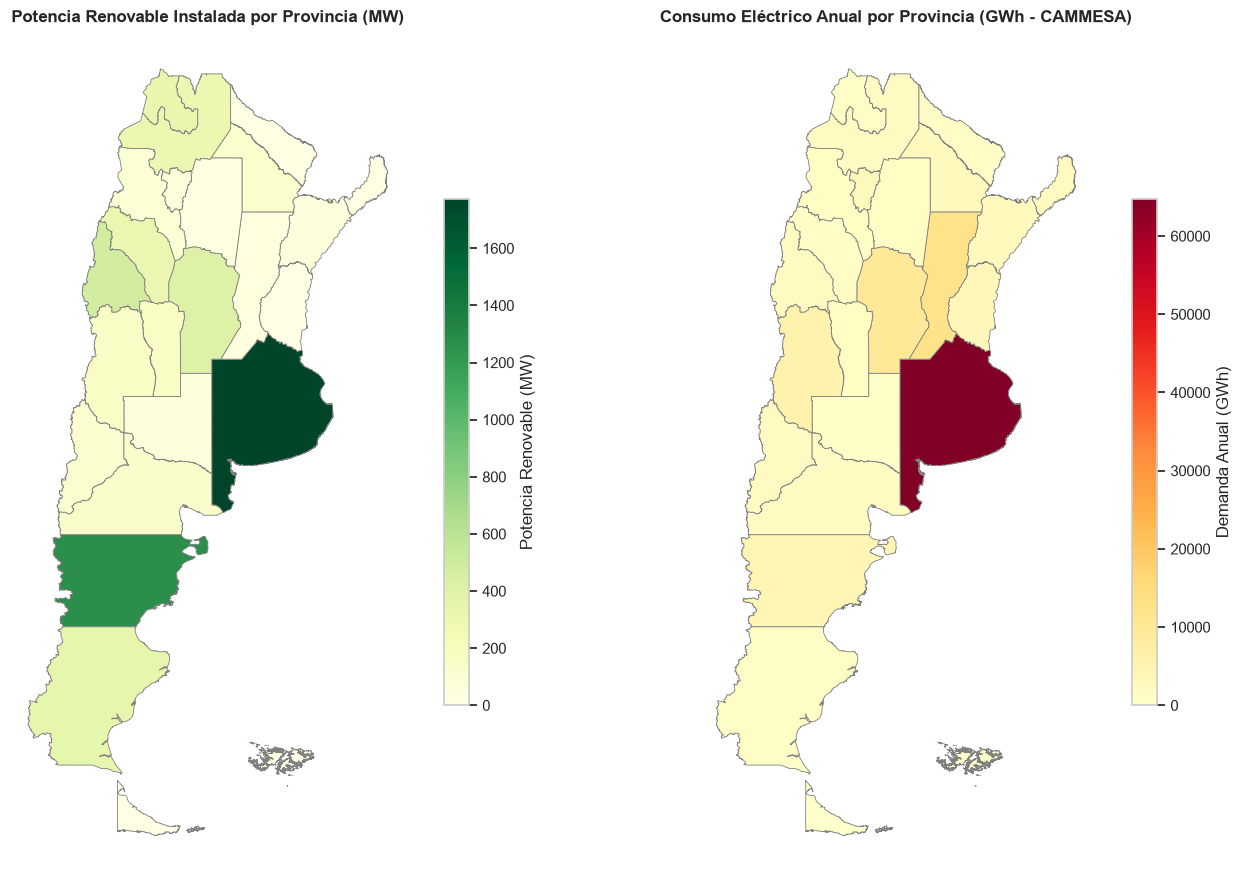

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 9))

# Mapa 1: Potencia Renovable por Provincia (MW)
gdf_prov_wgs.plot(
    column='potencia_renovable_mw',
    cmap='YlGn',
    edgecolor='gray',
    linewidth=0.6,
    legend=True,
    legend_kwds={'label': 'Potencia Renovable (MW)', 'shrink': 0.6},
    ax=axes[0]
)
axes[0].set_title('Potencia Renovable Instalada por Provincia (MW)', fontsize=12, fontweight='bold')
axes[0].set_axis_off()

# Mapa 2: Demanda Eléctrica Anual por Provincia (GWh - CAMMESA)
gdf_prov_wgs.plot(
    column='demanda_anual_gwh',
    cmap='YlOrRd',
    edgecolor='gray',
    linewidth=0.6,
    legend=True,
    legend_kwds={'label': 'Demanda Anual (GWh)', 'shrink': 0.6},
    ax=axes[1]
)
axes[1].set_title('Consumo Eléctrico Anual por Provincia (GWh - CAMMESA)', fontsize=12, fontweight='bold')
axes[1].set_axis_off()

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_04_generacion_vs_demanda_provincial.png'), dpi=150, bbox_inches='tight')
plt.show()

#### 4.5. Mapa de Calor (Heatmap) de Correlación y Consumo Mensual por Región
Siguiendo el bloque de Mapas de Calor de la Unidad 1, armamos una matriz de correlación con `seaborn` (usando máscara triangular superior `np.triu`) y un heatmap de la demanda eléctrica mes a mes según la región del país.

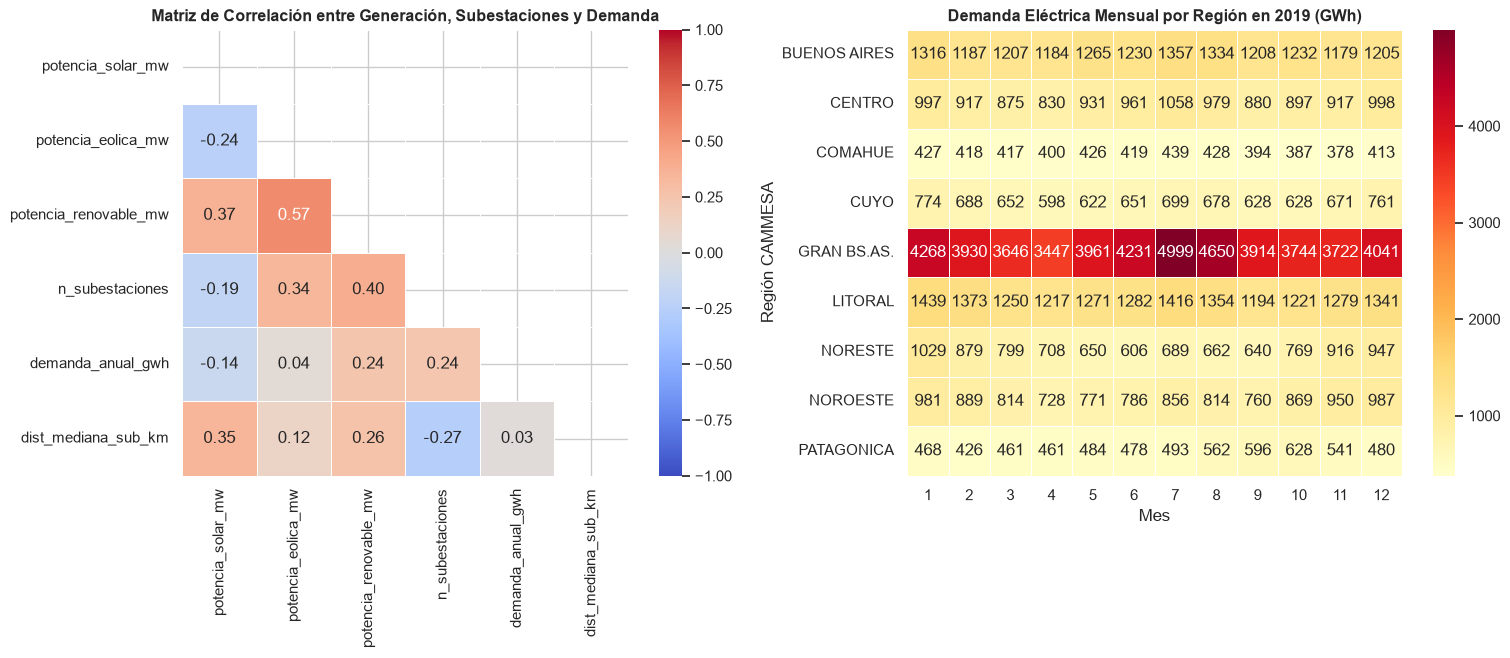

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

# 1. Heatmap de correlación entre variables provinciales
columnas_corr = [
    'potencia_solar_mw', 'potencia_eolica_mw', 'potencia_renovable_mw',
    'n_subestaciones', 'demanda_anual_gwh', 'dist_mediana_sub_km'
]
corr = gdf_prov_datos[columnas_corr].corr(method='spearman')
mascara = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(
    corr,
    mask=mascara,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1, vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    ax=axes[0]
)
axes[0].set_title('Matriz de Correlación entre Generación, Subestaciones y Demanda', fontsize=11.5, fontweight='bold')

# 2. Heatmap de consumo eléctrico mensual por región (en GWh)
tabla_mes_region = (
    df_demanda[df_demanda['anio'] == 2019]
    .groupby(['region', 'mes'])['demanda_MWh']
    .sum()
    .unstack() / 1000
)

sns.heatmap(
    tabla_mes_region,
    annot=True,
    fmt='.0f',
    cmap='YlOrRd',
    linewidths=0.5,
    ax=axes[1]
)
axes[1].set_title('Demanda Eléctrica Mensual por Región en 2019 (GWh)', fontsize=11.5, fontweight='bold')
axes[1].set_xlabel('Mes')
axes[1].set_ylabel('Región CAMMESA')

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_05_heatmaps_correlacion_estacionalidad.png'), dpi=150, bbox_inches='tight')
plt.show()

#### 4.6. Mapa Interactivo con `Folium`
Por último, creamos un mapa web interactivo con `Folium` que combina la capa coroplética de consumo eléctrico por provincia, los tooltips informativos al pasar el mouse y la ubicación de los parques renovables con la distancia a su subestación más cercana.

In [13]:
# Simplificar levemente los bordes de provincias para que el archivo HTML sea liviano
gdf_prov_folium = gdf_prov_wgs.copy()
gdf_prov_folium['geometry'] = gdf_prov_folium.geometry.simplify(tolerance=0.02, preserve_topology=True)
gdf_prov_folium[['potencia_renovable_mw', 'demanda_anual_gwh']] = gdf_prov_folium[['potencia_renovable_mw', 'demanda_anual_gwh']].round(1)

# Crear mapa base centrado en Argentina
m = folium.Map(location=[-38.0, -64.0], zoom_start=4, tiles='CartoDB positron')

# Capa coroplética de demanda eléctrica por provincia
folium.Choropleth(
    geo_data=gdf_prov_folium.__geo_interface__,
    name='Demanda Eléctrica por Provincia (GWh)',
    data=gdf_prov_folium,
    columns=['provincia', 'demanda_anual_gwh'],
    key_on='feature.properties.provincia',
    fill_color='YlOrRd',
    fill_opacity=0.5,
    line_opacity=0.5,
    legend_name='Demanda Eléctrica Anual (GWh)'
).add_to(m)

# Tooltips al pasar el mouse por cada provincia
folium.GeoJson(
    gdf_prov_folium[['provincia', 'potencia_renovable_mw', 'n_subestaciones', 'demanda_anual_gwh', 'geometry']].__geo_interface__,
    name='Datos por Provincia',
    style_function=lambda x: {'fillOpacity': 0, 'color': 'transparent'},
    tooltip=folium.GeoJsonTooltip(
        fields=['provincia', 'potencia_renovable_mw', 'n_subestaciones', 'demanda_anual_gwh'],
        aliases=['Provincia:', 'Potencia Renovable (MW):', 'Subestaciones AT:', 'Demanda Anual (GWh):']
    )
).add_to(m)

# Agregar puntos de los parques renovables
grupo_parques = folium.FeatureGroup(name='Parques de Energías Renovables')
for _, row in gdf_parques.iterrows():
    color_punto = colores_tec.get(row['tecnologia_limpia'], 'blue')
    texto_tooltip = (
        f"{row['nombre']} ({row['tecnologia_limpia']}) - "
        f"{row['potencia_mw']:.1f} MW | Subestación a {row['dist_subestacion_km']:.1f} km"
    )
    folium.CircleMarker(
        location=[row['latitud'], row['longitud']],
        radius=5,
        color='black',
        weight=1,
        fill=True,
        fill_color=color_punto,
        fill_opacity=0.85,
        tooltip=texto_tooltip
    ).add_to(grupo_parques)

grupo_parques.add_to(m)
folium.LayerControl().add_to(m)

m.save('mapa_interactivo_energias_renovables.html')
print('Mapa guardado como mapa_interactivo_energias_renovables.html')

Mapa guardado como mapa_interactivo_energias_renovables.html


---
### 5. Conclusiones

1. **Distribución regional por tecnología (Norte solar vs. Sur eólico):**
   El análisis exploratorio y los gráficos de latitud confirman la hipótesis planteada por el grupo. Los parques solares fotovoltaicos se ubican en el norte y centro-oeste del país (principalmente entre los -23° y -34° de latitud sur, en provincias como San Juan, Jujuy, Salta, Catamarca y La Rioja), mientras que los parques eólicos se concentran hacia el sur (por debajo de los -36° de latitud sur, en Chubut, Santa Cruz, Río Negro, Neuquén y el sur de Buenos Aires). Además, los parques eólicos son los que aportan la mayor potencia instalada acumulada dentro de las renovables.

2. **Proximidad a las Estaciones Transformadoras y transporte eléctrico:**
   A partir del cálculo de distancias con `cKDTree` en coordenadas proyectadas (`EPSG:32720`), se observa que más de la mitad de los parques renovables se ubican a una distancia corta o media (menos de 30 km) de una Estación Transformadora de Alta Tensión, lo cual es fundamental para poder elevar la tensión (a 132 kV o 500 kV) y evitar pérdidas de energía en el transporte.
   Por otro lado, los casos donde la distancia da mayor a 60 km corresponden a dos situaciones: proyectos ubicados en zonas más aisladas del NOA o la Patagonia que requieren nuevas obras de interconexión, o bien parques en provincias como Córdoba y Santa Fe donde se conectan a subestaciones provinciales de 132 kV que no figuran en el padrón nacional de subestaciones troncales.

3. **Relación entre generación renovable y consumo provincial:**
   Al cruzar los polígonos provinciales del IGN con los datos de demanda de CAMMESA, queda claro el desbalance territorial: Buenos Aires (incluyendo CABA), Santa Fe y Córdoba concentran la mayor parte del consumo eléctrico del país (sobre todo en los meses de verano e invierno, como muestra el mapa de calor estacional), mientras que provincias con baja demanda local como Chubut, Santa Cruz, La Rioja, San Juan y Jujuy cuentan con una gran capacidad de generación renovable que debe transportarse a través de las líneas de Alta Tensión hacia el centro del país.

4. **Suficiencia de la Red, Caídas de Tensión e Impacto de la Expansión Minera:**

   Limitaciones de transporte y necesidad de nuevas subestaciones: Aunque la generación nacional parece suficiente, el análisis espacial demuestra que la infraestructura de transporte opera al límite. Para evitar caídas de tensión por la distancia desde los polos renovables, es indispensable crear y ampliar subestaciones en la franja central (Córdoba, Santa Fe y Buenos Aires).

   Impacto del boom minero-industrial: El desarrollo de proyectos mineros (litio y cobre) modificará drásticamente la demanda eléctrica nacional. Al tratarse de consumos electrointensivos en zonas alejadas, se requerirá un rediseño urgente del SADI y la instalación de nuevas subestaciones estratégicas en áreas cordilleranas.   